# 03 — Experiment 2 (Candidate C): change-of-direction cost relative to the athlete's own capacity — simulation

**Question.** Can we define, compute and *measure* the time an athlete loses in direction changes compared with the
minimum feasible time given **their own** physical limits? And does that measure capture something beyond
straight-line sprint speed and beyond conventional COD measures?

**Guardrails.**
- Synthetic athletes and trajectories with known ground truth; **no NFL outcome data**.
- Drill geometries approximate the combine drills; they are not official specifications.
- Simulated athletes have a technique trait that is, by construction, independent of speed in the base case. The simulation can therefore show that the metric **can** isolate such a trait. It **cannot** show that the trait exists in real players or matters for performance.

In [1]:
import sys, warnings, json, time
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src")); warnings.filterwarnings("ignore")
import numpy as np, polars as pl, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from nfl_bdb.visualization import style
from nfl_bdb.features.change_direction_cost import (AthleteLimits, path_from_waypoints, cone_turn_path, drill_paths,
    min_time_profile, min_time_nlp, linear_sprint_time, simulate_execution, estimate_path, segment_time, ccmt_cost)
style.apply(); pl.Config.set_tbl_rows(80); pl.Config.set_tbl_width_chars(220); pl.Config.set_tbl_hide_dataframe_shape(True)
FIG = ROOT / "reports" / "figures"
def save(fig, name): fig.savefig(FIG / f"sim_c_{name}.png", bbox_inches="tight", dpi=150)
LIM = AthleteLimits(A0=8.9, S0=11.6, D=6.5, C=7.0)

## 1 · Formulation
A fixed path is parameterised by arc length s ∈ [0, L], with curvature κ(s). The decision variable is the speed profile v(s) ≥ 0, chosen to minimise the traversal time

  **T = ∫₀ᴸ ds / v(s)**

subject to:

| # | Constraint | Meaning | Parameter source |
|---|---|---|---|
| C1 | v ≤ S0 | maximal speed | Experiment 1 estimator |
| C2 | v dv/ds ≤ A0 (1 − v/S0) · g | propulsion follows the athlete's A–S line (Hill–Keller form) | Experiment 1 estimator |
| C3 | v dv/ds ≥ −D · g | braking capacity | *assumed estimable* (frontier of braking); not yet shown |
| C4 | v² κ ≤ C(v) | lateral (centripetal) capacity; C constant or C(1 − β v/S0) | *assumed estimable*; weakest link |
| C5 | v = 0 at reversals | touch-and-return points (shuttle, 3-cone) | drill layout |
| C6 | v(0) = 0 | standing start | drill protocol |

- **Coupling.** g = 1 means independent limits. g = √(1 − (v²κ/C)²) couples tangential and lateral capacity (the "friction ellipse", or g–g diagram, of vehicle dynamics).
- **Solution method.**
  - With g = 1 the optimum is the pointwise minimum of the curvature/speed cap, a forward maximal-propulsion pass and a backward maximal-braking pass. This is the vehicle-dynamics construction for minimum-time travel on a fixed path (Velenis & Tsiotras 2008; Lipp & Boyd 2014, cited for the method).
  - We verify optimality against a direct-transcription NLP (§2).
- **Decomposition** of the measured time over the timed segment:

  T_obs = T*_ref + (T*_own − T*_ref) + (T_obs − T*_own),  where **K = T*_own − T*_ref** is the *capacity cost* and **E = T_obs − T*_own** is the *execution cost*.

**Is optimal control appropriate?**
- The fixed-path problem is a one-dimensional optimal-control problem in s. For decoupled limits it has an exact, O(N) solution, so a general-purpose solver is unnecessary.
- **Free-path** optimisation (also choosing the path around cones) is a harder, non-convex trajectory-optimisation problem (§3.2 shows why it matters). We do not attempt it here.
- Optimal control of human running itself is not new (Keller 1973; Maroński 1996; Greene 1985 and Chang & Kram 2007 on turns).

## 2 · Verification of the solver

In [2]:
p40 = path_from_waypoints([[0,0],[40,0]], [])
_, T40, _ = min_time_profile(p40, LIM)
print(f"straight 40 yd: forward–backward {T40:.4f}s  vs closed-form mono-exponential {linear_sprint_time(40, LIM):.4f}s")
rows=[]
for name in ["cut_45","cut_90","cut_135","three_cone","shuttle_5_10_5"]:
    for ell in (False, True):
        t0=time.time(); r=min_time_nlp(drill_paths()[name], AthleteLimits(A0=8.9,S0=11.6,D=6.5,C=7.0,ellipse=ell), n_nodes=60)
        rows.append(dict(path=name, coupling="friction ellipse" if ell else "independent", T_forward_backward=round(r["T_fb_same_grid"],5),
                         T_NLP_best=round(r["T_nlp"],5), rel_diff_pct=round(100*(r["T_nlp"]-r["T_fb_same_grid"])/r["T_fb_same_grid"],3),
                         max_abs_speed_diff=round(float(np.max(np.abs(r["v_nlp"]-r["v_fb"]))),3)))
verif=pl.DataFrame(rows); verif

straight 40 yd: forward–backward 4.7175s  vs closed-form mono-exponential 4.7167s


path,coupling,T_forward_backward,T_NLP_best,rel_diff_pct,max_abs_speed_diff
str,str,f64,f64,f64,f64
"""cut_45""","""independent""",3.36499,3.36499,-0.0,0.0
"""cut_45""","""friction ellipse""",3.51855,3.48529,-0.945,0.216
"""cut_90""","""independent""",3.5355,3.5355,-0.0,0.0
"""cut_90""","""friction ellipse""",3.69506,3.65307,-1.136,0.241
"""cut_135""","""independent""",3.64268,3.64268,-0.0,0.0
"""cut_135""","""friction ellipse""",3.88723,3.7865,-2.591,0.504
"""three_cone""","""independent""",9.29438,9.29437,-0.0,0.0
"""three_cone""","""friction ellipse""",10.03529,9.75885,-2.755,0.707
"""shuttle_5_10_5""","""independent""",5.30924,5.30923,-0.0,0.0


**Reading.**
- With **independent** limits the forward–backward profile equals the best NLP solution, found from three starts with identical discrete constraints, to numerical precision. That is consistent with optimality; it is a numerical check, not a proof.
- With the **friction-ellipse** coupling the NLP finds *faster* profiles on curved paths, so the simple forward–backward pass is **not** optimal there. A coupled model would need direct transcription, at a cost of seconds rather than milliseconds per path.

The base model below uses independent limits. Coupling is an untested modelling choice.

## 3 · How curvature affects minimum feasible time
### 3.1 Turn angle × radius on a fixed path (10 yd straight → turn → 8 yd straight)

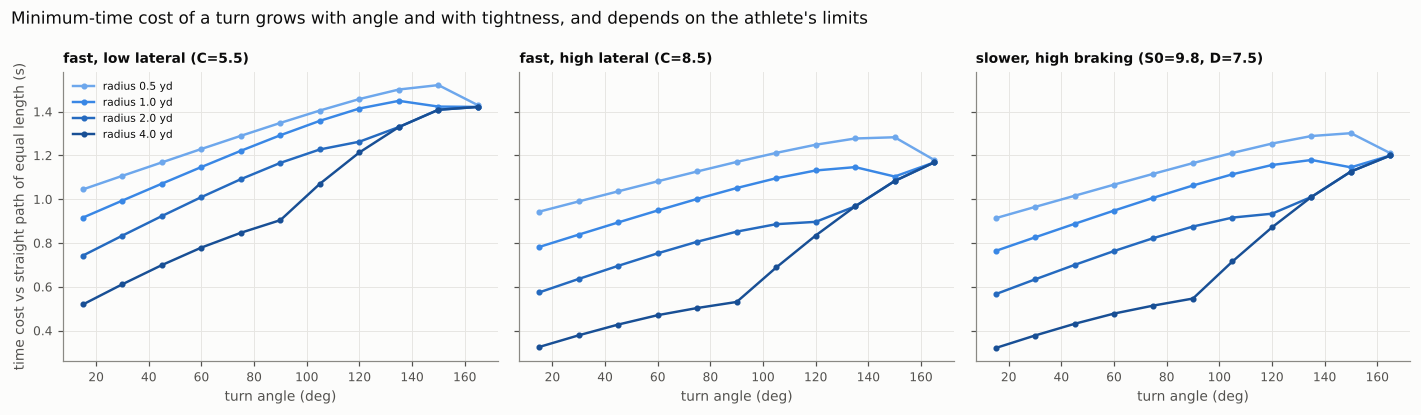

In [3]:
arche = {"fast, low lateral (C=5.5)": AthleteLimits(A0=8.9,S0=11.6,D=6.5,C=5.5),
         "fast, high lateral (C=8.5)": AthleteLimits(A0=8.9,S0=11.6,D=6.5,C=8.5),
         "slower, high braking (S0=9.8, D=7.5)": AthleteLimits(A0=7.5,S0=9.8,D=7.5,C=7.0)}
angles=np.arange(15,166,15); radii=[0.5,1.0,2.0,4.0]
def turn_path(theta, r):
    th=np.radians(theta); return path_from_waypoints([[0,0],[10,0],[10+8*np.cos(th),8*np.sin(th)]],[r])
fig,axes=plt.subplots(1,3,figsize=(13,3.8),sharey=True)
for ax,(lab,lim) in zip(axes,arche.items()):
    for i,r in enumerate(radii):
        cost=[]
        for a in angles:
            p=turn_path(a,r); _,T,_=min_time_profile(p,lim); _,Ts,_=min_time_profile(path_from_waypoints([[0,0],[p.length,0]],[]),lim)
            cost.append(T-Ts)
        ax.plot(angles,cost,marker="o",ms=3,color=style.SEQ_BLUE[2+i],label=f"radius {r} yd")
    ax.set_title(lab,loc="left",fontsize=9); ax.set_xlabel("turn angle (deg)")
axes[0].set_ylabel("time cost vs straight path of equal length (s)"); axes[0].legend(fontsize=7)
fig.suptitle("Minimum-time cost of a turn grows with angle and with tightness, and depends on the athlete's limits",x=.01,ha="left",fontsize=11)
fig.tight_layout(); save(fig,"curvature_cost")

### 3.2 Turning *around* a cone: the optimal radius is athlete-specific (path choice matters)

turn_deg,athlete,optimal_radius_yd,T_min,penalty_if_r_1yd,penalty_if_r_3yd
i64,str,f64,f64,f64,f64
90,"""fast, low lateral (C=5.5)""",0.2,4.357,0.078,0.244
90,"""fast, high lateral (C=8.5)""",1.3,4.186,0.003,0.032
90,"""slower, high braking (S0=9.8, …",0.5,4.566,0.008,0.091
180,"""fast, low lateral (C=5.5)""",0.2,4.656,0.449,1.105
180,"""fast, high lateral (C=8.5)""",0.2,4.479,0.249,0.673
180,"""slower, high braking (S0=9.8, …",0.2,4.836,0.332,0.849


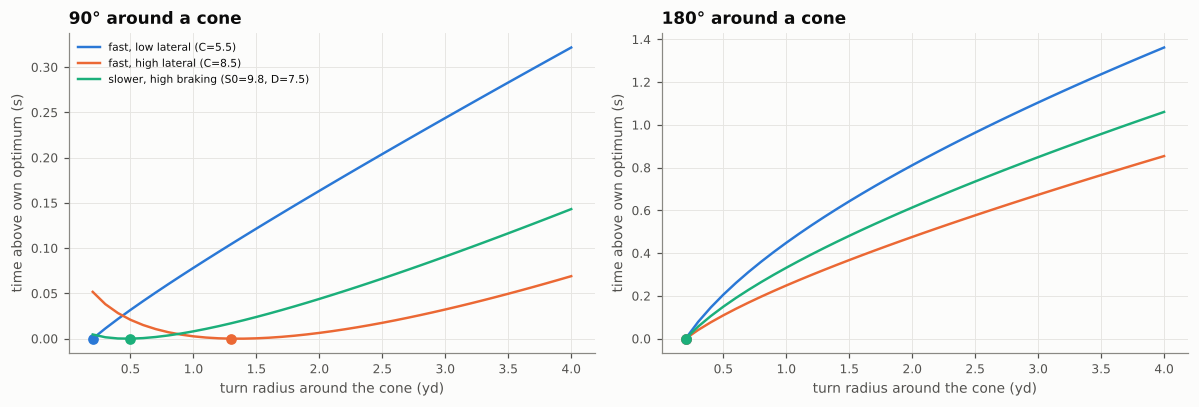

In [4]:
rs=np.linspace(0.2,4.0,39)
fig,axes=plt.subplots(1,2,figsize=(11,3.8))
tab=[]
for ax,turn in zip(axes,(90,180)):
    for i,(lab,lim) in enumerate(arche.items()):
        T=np.array([min_time_profile(cone_turn_path(r,turn),lim)[1] for r in rs])
        ax.plot(rs,T-T.min(),color=style.SERIES[i],label=lab); ax.plot(rs[T.argmin()],0,"o",color=style.SERIES[i],ms=6)
        tab.append(dict(turn_deg=turn, athlete=lab, optimal_radius_yd=round(float(rs[T.argmin()]),2), T_min=round(float(T.min()),3),
                        penalty_if_r_1yd=round(float(np.interp(1.0,rs,T)-T.min()),3), penalty_if_r_3yd=round(float(np.interp(3.0,rs,T)-T.min()),3)))
    ax.set_xlabel("turn radius around the cone (yd)"); ax.set_ylabel("time above own optimum (s)"); ax.set_title(f"{turn}° around a cone",loc="left")
axes[0].legend(fontsize=7)
fig.tight_layout(); save(fig,"optimal_radius")
pl.DataFrame(tab)

**Implication.**
- A *fixed-path* CCMT measures how well the athlete used their limits on the path they chose. It does **not** charge them for choosing a sub-optimal path.
- Charging for path choice needs free-path optimisation between cones. That is possible for the standardised combine drills (known geometry), but not for in-game cuts, where the "intended" path is unknown.

### 3.3 Lateral-limit model sensitivity (the least identifiable constraint)

In [5]:
rows=[]
D_=drill_paths()
for name in ["cut_45","cut_90","cut_135","three_cone"]:
    base=min_time_profile(D_[name],LIM)[1]
    for lab,lim in {"constant C=7":LIM,"C(v)=10(1-0.5 v/S0)":AthleteLimits(A0=8.9,S0=11.6,D=6.5,C=10.0,lat_slope=0.5),
                    "no lateral limit":AthleteLimits(A0=8.9,S0=11.6,D=6.5,C=7.0,lateral=False),"constant C=5":AthleteLimits(A0=8.9,S0=11.6,D=6.5,C=5.0)}.items():
        rows.append(dict(path=name, lateral_model=lab, T_star=round(min_time_profile(D_[name],lim)[1],3), diff_vs_constant7=round(min_time_profile(D_[name],lim)[1]-base,3)))
pl.DataFrame(rows).pivot(on="lateral_model", index="path", values="diff_vs_constant7")

path,constant C=7,C(v)=10(1-0.5 v/S0),no lateral limit,constant C=5
str,f64,f64,f64,f64
"""cut_45""",0.0,-0.086,-0.977,0.12
"""cut_90""",0.0,-0.114,-1.144,0.166
"""cut_135""",0.0,-0.12,-1.333,0.154
"""three_cone""",0.0,-0.419,-3.498,0.68


Differences of tenths of a second, which is the same order as plausible execution costs. **The lateral-limit specification is therefore a first-order assumption.** Greene's (1985) speed–radius model is the obvious next candidate to implement once the full text is read.

## 4 · Theoretical vs actual: one synthetic athlete on the 3-cone drill

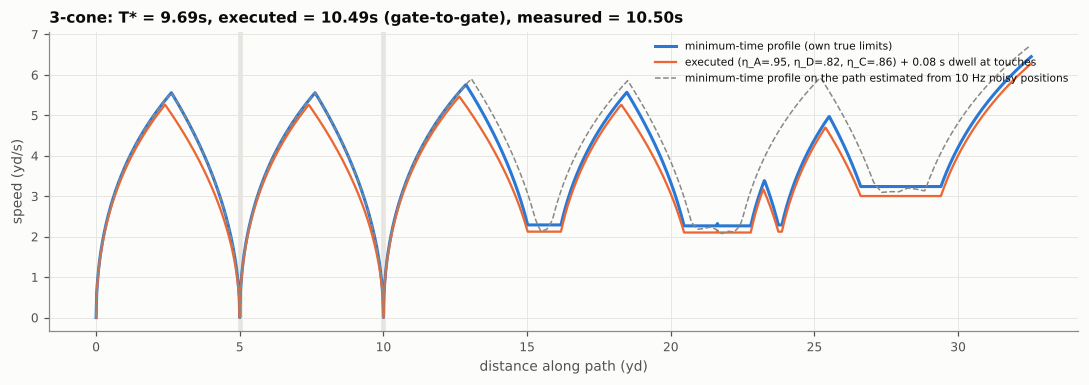

In [6]:
p=D_["three_cone"]; rng=np.random.default_rng(3)
v_opt,_,_=min_time_profile(p,LIM)
ex=simulate_execution(p,LIM,(0.95,0.82,0.86),0.08,noise_sd=0.01,rng=rng)
P,Tm,s0,sp=estimate_path(ex["x"],ex["y"],finish_point=ex["finish_point"],finish_dir=ex["finish_dir"])
v_meas=np.interp(P.s, np.r_[0,np.cumsum(np.hypot(np.diff(ex['x']),np.diff(ex['y'])))][:len(sp)][:len(sp)], sp[:len(sp)]) if False else None
fig,ax=plt.subplots(figsize=(10,3.6))
ax.plot(p.s,v_opt,color=style.SERIES[0],lw=2,label="minimum-time profile (own true limits)")
ax.plot(p.s,ex["v_profile"],color=style.SERIES[1],lw=1.5,label="executed (η_A=.95, η_D=.82, η_C=.86) + 0.08 s dwell at touches")
v_est,_,_=min_time_profile(P,LIM)
ax.plot(P.s,v_est,color=style.MUTED,lw=1,ls="--",label="minimum-time profile on the path estimated from 10 Hz noisy positions")
for s_stop in p.s[p.stop]: ax.axvline(s_stop,color=style.GRID,lw=3,zorder=0)
ax.set_xlabel("distance along path (yd)"); ax.set_ylabel("speed (yd/s)"); ax.legend(fontsize=7,loc="upper right")
ax.set_title(f"3-cone: T* = {segment_time(p,LIM,0.5):.2f}s, executed = {ex['T_true']-np.interp(0.5,p.s,ex['t_profile']):.2f}s (gate-to-gate), measured = {Tm:.2f}s",loc="left",fontsize=10)
fig.tight_layout(); save(fig,"theory_vs_actual")

The estimated-path optimum (dashed) is *faster* than the true-path optimum: smoothing 10 Hz positions rounds the tight turns, so curvature is under-estimated. This **constant per-drill bias** is quantified in §5.

## 5 · Population study (disjoint seeds; `scripts/run_cod_simulation.py`)

In [7]:
run_id=(ROOT/"experiments/cod_sim/LATEST").read_text().strip()
R=pl.read_parquet(ROOT/f"experiments/cod_sim/{run_id}/results.parquet")
print("run",run_id,"| rows",R.height,"| cells",R["cell"].n_unique(),"| athletes per cell",R.filter(pl.col("cell")=="base")["athlete"].n_unique())
METRICS={"total_time":"total time","codd":"COD deficit","codd_pct":"% COD deficit","cod_speed":"COD speed (−)","peak_braking":"peak braking (−)",
         "E_hat":"CCMT execution cost","E_ratio":"CCMT execution ratio","E_nominal":"CCMT, nominal path","E_ref_only":"ablation: reference limits only",
         "E_no_lateral":"ablation: no lateral limit","K_hat":"CCMT capacity cost"}
SIGN={"cod_speed":-1,"peak_braking":-1}   # orient so that larger = worse for every metric
def athlete_table(cell):
    d=R.filter(pl.col("cell")==cell)
    agg=d.group_by("athlete","drill").agg([pl.col(m).mean() for m in METRICS]+[pl.col(c).first() for c in ("z","T40_true","S0","A0","D","C","pos")]+[pl.col("E_true").mean()])
    return agg
def corr_table(cell):
    a=athlete_table(cell); rows=[]
    for dr in a["drill"].unique().sort().to_list():
        q=a.filter(pl.col("drill")==dr)
        for m,lab in METRICS.items():
            x=SIGN.get(m,1)*q[m].to_numpy()
            r_E=spearmanr(x,q["E_true"]).statistic; r_z=spearmanr(x,-q["z"].to_numpy()).statistic; r_T=spearmanr(x,q["T40_true"]).statistic
            # partial correlation with -z controlling for true 40 time (ranks)
            from scipy.stats import rankdata
            X=np.c_[np.ones(len(x)),rankdata(q["T40_true"])]
            res=lambda y: y-X@np.linalg.lstsq(X,y,rcond=None)[0]
            r_zp=np.corrcoef(res(rankdata(x)),res(rankdata(-q["z"].to_numpy())))[0,1]
            rows.append(dict(drill=dr,metric=lab,r_with_true_E=round(r_E,3),r_with_poor_technique=round(r_z,3),r_with_40_time=round(r_T,3),partial_r_technique_given_40=round(r_zp,3)))
    return pl.DataFrame(rows)
base_corr=corr_table("base"); base_corr

run 20261120T192154Z | rows 36000 | cells 15 | athletes per cell 300


drill,metric,r_with_true_E,r_with_poor_technique,r_with_40_time,partial_r_technique_given_40
str,str,f64,f64,f64,f64
"""cut_135""","""total time""",0.465,0.268,0.774,0.394
"""cut_135""","""COD deficit""",0.626,0.455,0.395,0.485
"""cut_135""","""% COD deficit""",0.556,0.475,-0.097,0.48
"""cut_135""","""COD speed (−)""",0.465,0.267,0.776,0.393
"""cut_135""","""peak braking (−)""",0.559,0.412,0.568,0.484
"""cut_135""","""CCMT execution cost""",0.637,0.568,0.152,0.571
"""cut_135""","""CCMT execution ratio""",0.56,0.542,-0.025,0.543
"""cut_135""","""CCMT, nominal path""",0.628,0.575,0.109,0.575
"""cut_135""","""ablation: reference limits onl…",0.471,0.318,0.312,0.327


How to read the table:
- **r_with_true_E**: Spearman correlation of the measured metric with the true execution cost. This is the measurement-validity target.
- **r_with_poor_technique**: correlation with −z, the latent technique trait.
- **r_with_40_time**: correlation with true straight-line sprint ability. *Lower is better* if the aim is to isolate COD from speed.
- **partial_r_technique_given_40**: rank partial correlation with poor technique, controlling for 40 time.
- Everything is oriented so that larger values mean worse.

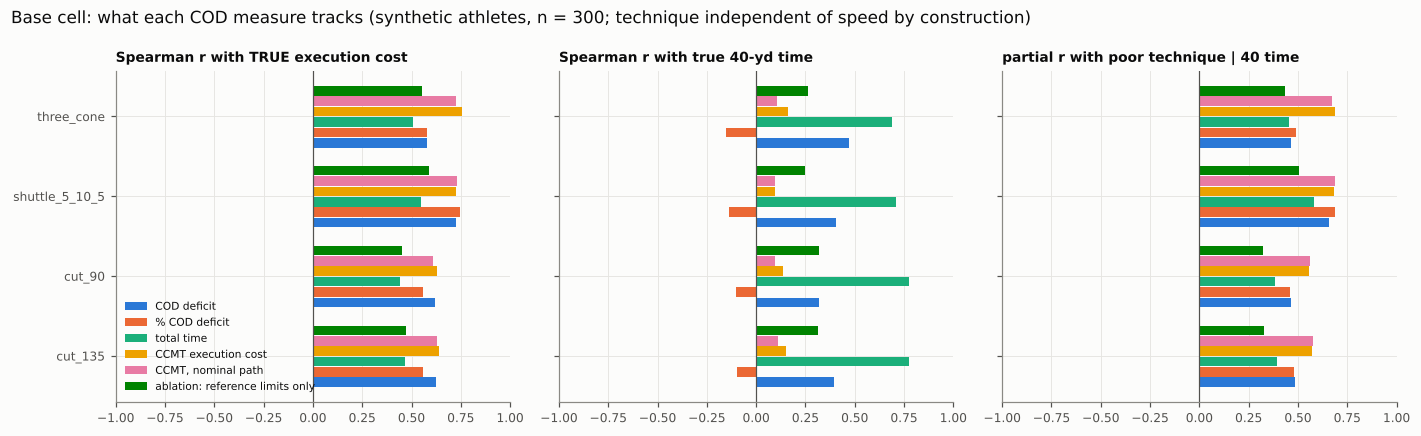

In [8]:
key=["COD deficit","% COD deficit","total time","CCMT execution cost","CCMT, nominal path","ablation: reference limits only"]
q=base_corr.filter(pl.col("metric").is_in(key))
fig,axes=plt.subplots(1,3,figsize=(13,4),sharey=True)
drills=q["drill"].unique().sort().to_list()
for ax,(col,lab) in zip(axes,[("r_with_true_E","Spearman r with TRUE execution cost"),("r_with_40_time","Spearman r with true 40-yd time"),("partial_r_technique_given_40","partial r with poor technique | 40 time")]):
    for i,m in enumerate(key):
        v=[q.filter((pl.col("metric")==m)&(pl.col("drill")==d))[col][0] for d in drills]
        ax.barh(np.arange(len(drills))+i*0.13-0.33,v,height=0.12,color=style.SERIES[i],label=m)
    ax.axvline(0,color=style.TEXT2,lw=.8); ax.set_title(lab,loc="left",fontsize=9); ax.set_xlim(-1,1)
axes[0].set_yticks(range(len(drills)),drills); axes[0].legend(fontsize=7,loc="lower left")
fig.suptitle("Base cell: what each COD measure tracks (synthetic athletes, n = 300; technique independent of speed by construction)",x=.01,ha="left",fontsize=11)
fig.tight_layout(); save(fig,"metric_validity")

### 5.1 Test–retest reliability (two attempts per drill)

In [9]:
def retest(cell):
    d=R.filter(pl.col("cell")==cell); rows=[]
    for dr in d["drill"].unique().sort().to_list():
        q=d.filter(pl.col("drill")==dr)
        a1=q.filter(pl.col("attempt")==1).sort("athlete"); a2=q.filter(pl.col("attempt")==2).sort("athlete")
        j=a1.join(a2,on="athlete",suffix="_2")
        for m,lab in METRICS.items():
            rows.append(dict(drill=dr,metric=lab,retest_r=round(float(np.corrcoef(j[m],j[f"{m}_2"])[0,1]),3)))
    return pl.DataFrame(rows).pivot(on="drill",index="metric",values="retest_r")
retest("base")

metric,cut_135,cut_90,shuttle_5_10_5,three_cone
str,f64,f64,f64,f64
"""total time""",0.995,0.994,0.992,0.995
"""COD deficit""",0.988,0.985,0.985,0.992
"""% COD deficit""",0.987,0.985,0.981,0.99
"""COD speed (−)""",0.996,0.996,0.993,0.995
"""peak braking (−)""",0.98,0.978,0.982,0.979
"""CCMT execution cost""",0.962,0.958,0.969,0.975
"""CCMT execution ratio""",0.962,0.96,0.97,0.975
"""CCMT, nominal path""",0.968,0.963,0.966,0.977
"""ablation: reference limits onl…",0.99,0.989,0.989,0.991


Attempt-to-attempt variation comes from small changes in η and dwell plus measurement noise (simulation assumption). The 40-yd sprint is a fixed athlete property in the simulation.

### 5.2 Bias of the measured execution cost (absolute seconds)

In [10]:
d=R.filter(pl.col("cell")=="base").with_columns((pl.col("E_hat")-pl.col("E_true")).alias("err_est_path"),(pl.col("E_nominal")-pl.col("E_true")).alias("err_nominal"))
d.group_by("drill").agg(pl.col("E_true").mean().round(3).alias("mean_true_E"),pl.col("err_est_path").mean().round(3).alias("bias_estimated_path"),pl.col("err_est_path").std().round(3).alias("sd_estimated_path"),
    pl.col("err_nominal").mean().round(3).alias("bias_nominal_path"),pl.col("err_nominal").std().round(3).alias("sd_nominal_path"),
    pl.corr("err_est_path","S0").round(3).alias("corr_bias_with_S0")).sort("drill")

drill,mean_true_E,bias_estimated_path,sd_estimated_path,bias_nominal_path,sd_nominal_path,corr_bias_with_S0
str,f64,f64,f64,f64,f64,f64
"""cut_135""",0.157,0.17,0.067,0.007,0.07,-0.036
"""cut_90""",0.147,0.199,0.065,0.007,0.069,-0.033
"""shuttle_5_10_5""",0.361,-0.002,0.123,0.002,0.123,-0.006
"""three_cone""",0.689,0.646,0.219,-0.001,0.246,-0.081


### 5.3 Sensitivity analysis (noise, sampling, smoothing, limit-estimation error, lateral limit unknown, technique–speed correlation)

In [11]:
cells=R["cell"].unique(maintain_order=True).to_list()
rows=[]
for c in cells:
    ct=corr_table(c)
    for m in ["CCMT execution cost","CCMT, nominal path","COD deficit","% COD deficit"]:
        q=ct.filter(pl.col("metric")==m)
        rows.append(dict(cell=c,metric=m,mean_r_true_E=round(q["r_with_true_E"].mean(),3),mean_r_40=round(q["r_with_40_time"].mean(),3),
                         mean_partial_technique=round(q["partial_r_technique_given_40"].mean(),3)))
sens=pl.DataFrame(rows)
sens.pivot(on="metric",index="cell",values="mean_r_true_E")

cell,CCMT execution cost,"CCMT, nominal path",COD deficit,% COD deficit
str,f64,f64,f64,f64
"""noise_0.0""",0.7,0.685,0.621,0.589
"""base""",0.686,0.674,0.638,0.61
"""noise_0.02""",0.671,0.66,0.588,0.594
"""noise_0.05""",0.688,0.699,0.616,0.63
"""fs_5""",0.661,0.701,0.597,0.555
"""fs_25""",0.736,0.723,0.645,0.596
"""window_5""",0.73,0.721,0.592,0.586
"""window_9""",0.672,0.661,0.601,0.585
"""limits_err_0""",0.987,0.997,0.653,0.583


cell,CCMT execution cost,"CCMT, nominal path",COD deficit,% COD deficit
str,f64,f64,f64,f64
"""noise_0.0""",0.126,0.093,0.405,-0.175
"""base""",0.137,0.101,0.399,-0.123
"""noise_0.02""",0.054,0.025,0.472,-0.117
"""noise_0.05""",0.059,0.096,0.441,-0.115
"""fs_5""",0.123,0.122,0.44,-0.184
"""fs_25""",0.116,0.09,0.441,-0.132
"""window_5""",0.057,0.043,0.404,-0.193
"""window_9""",0.182,0.144,0.526,-0.083
"""limits_err_0""",0.264,0.224,0.485,-0.074


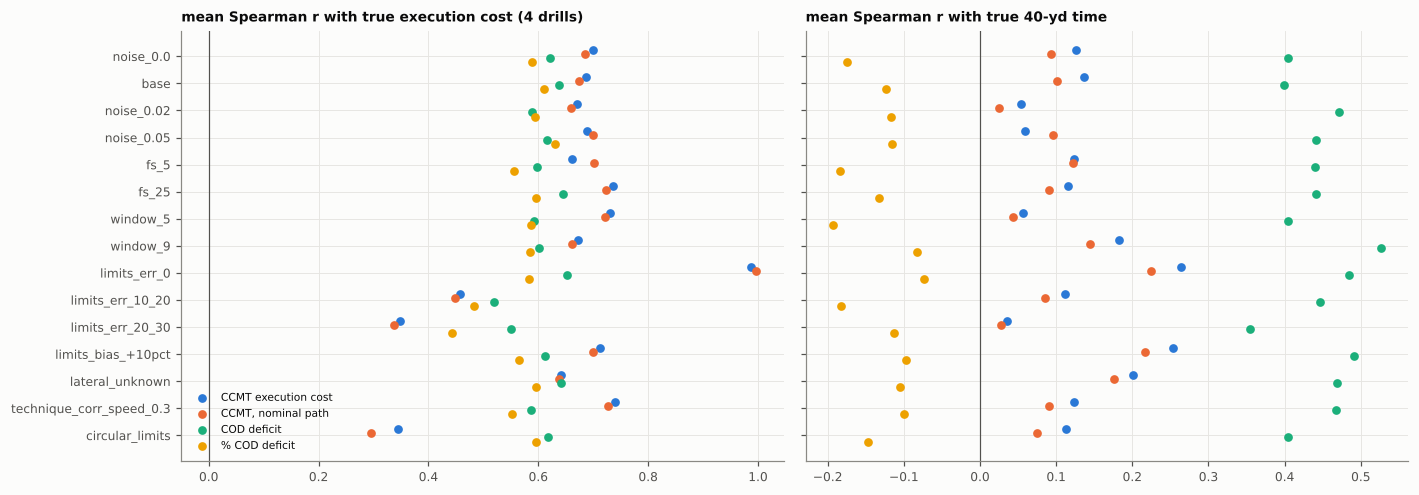

In [12]:
fig,axes=plt.subplots(1,2,figsize=(13,4.6),sharey=True)
order=cells
for ax,(col,lab) in zip(axes,[("mean_r_true_E","mean Spearman r with true execution cost (4 drills)"),("mean_r_40","mean Spearman r with true 40-yd time")]):
    for i,m in enumerate(["CCMT execution cost","CCMT, nominal path","COD deficit","% COD deficit"]):
        v=[sens.filter((pl.col("cell")==c)&(pl.col("metric")==m))[col][0] for c in order]
        ax.scatter(v,np.arange(len(order))+(i-1.5)*0.15,s=22,color=style.SERIES[i],label=m,zorder=3)
    ax.axvline(0,color=style.TEXT2,lw=.8); ax.set_title(lab,loc="left",fontsize=9)
axes[0].set_yticks(range(len(order)),order,fontsize=8); axes[0].invert_yaxis(); axes[0].legend(fontsize=7,loc="lower left")
fig.tight_layout(); save(fig,"sensitivity")
sens.pivot(on="metric",index="cell",values="mean_r_40")

### 5.4 Identifiability warning: limits estimated from the athlete's own COD behaviour
In the `circular_limits` cell the braking and lateral limits are "estimated" from the athlete's own drill behaviour, so they already include the athlete's inefficiency. The execution cost should then collapse, because an athlete who never brakes hard is indistinguishable from one who cannot.

In [13]:
pl.concat([corr_table(c).filter(pl.col("metric")=="CCMT execution cost").with_columns(pl.lit(c).alias("cell")) for c in ("base","circular_limits")]).select("cell","drill","r_with_true_E","r_with_poor_technique","partial_r_technique_given_40")

cell,drill,r_with_true_E,r_with_poor_technique,partial_r_technique_given_40
str,str,f64,f64,f64
"""base""","""cut_135""",0.637,0.568,0.571
"""base""","""cut_90""",0.628,0.555,0.556
"""base""","""shuttle_5_10_5""",0.727,0.683,0.684
"""base""","""three_cone""",0.754,0.682,0.687
"""circular_limits""","""cut_135""",0.273,0.233,0.227
"""circular_limits""","""cut_90""",0.259,0.212,0.207
"""circular_limits""","""shuttle_5_10_5""",0.484,0.462,0.459
"""circular_limits""","""three_cone""",0.358,0.309,0.305


## 6 · Conclusions (simulation only)
The interpretation, the unvalidatable assumptions and the recommendation are in `research_notes/candidate_c_feasibility.md`; all numbers there come from the tables above.